# Feature selection

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.feature_selection import VarianceThreshold, SelectFromModel
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold, cross_val_score


In [2]:
wells = pd.read_csv("wells_nitrate.csv")
# made in crop_mapping_eda.ipynb
crops = pd.read_csv("well_crop_features_all.csv")
df = wells.merge(crops, on="well_id")

raw_cols = [c for c in crops.columns if c != "well_id"]
x = df[raw_cols] # the 67 original features
y = df["exceeds_10mgL"] # target: over the 10 mg/L limit
corr_target = x.corrwith(df["nitrate_median_mgL"], method="spearman")
log = []

/usr/local/lib/python3.10/dist-packages/pandas/core/nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


In [3]:
#print(x)
print(x.columns.unique())

Index(['pct_veg_berry_1000m_1997', 'pct_vineyard_1000m_1997',
       'pct_orchard_1000m_1997', 'pct_grain_field_pasture_1000m_1997',
       'pct_idle_fallow_1000m_1997', 'pct_urban_1000m_1997',
       'pct_cropland_1000m_1997', 'pct_veg_berry_1000m_2014',
       'pct_vineyard_1000m_2014', 'pct_orchard_1000m_2014',
       'pct_grain_field_pasture_1000m_2014', 'pct_idle_fallow_1000m_2014',
       'pct_urban_1000m_2014', 'pct_cropland_1000m_2014',
       'pct_veg_berry_1000m_2016', 'pct_vineyard_1000m_2016',
       'pct_orchard_1000m_2016', 'pct_grain_field_pasture_1000m_2016',
       'pct_idle_fallow_1000m_2016', 'pct_urban_1000m_2016',
       'pct_cropland_1000m_2016', 'pct_veg_berry_1000m_2018',
       'pct_vineyard_1000m_2018', 'pct_orchard_1000m_2018',
       'pct_grain_field_pasture_1000m_2018', 'pct_idle_fallow_1000m_2018',
       'pct_urban_1000m_2018', 'pct_cropland_1000m_2018',
       'crop_cycles_1000m_2018', 'pct_multicrop_1000m_2018',
       'pct_veg_berry_1000m_2020', 'pct_v

## 1. Domain filter

In [4]:
# Urban: maps after 1997 don't map towns, so 0% urban means "not mapped".
# History: only kept for vegetables/berries, the high-nitrogen crops. Old maps of every other crop would add dozens of columns with no clear reason.

urban = [c for c in x.columns if "urban" in c]
history = [c for c in x.columns if not c.endswith("2023") and "veg_berry" not in c and "urban" not in c]

for c in urban:
    log.append({"feature": c, "step": "domain", "decision": "drop", "reason": "urban only mapped in 1997"})
for c in history:
    log.append({"feature": c, "step": "domain", "decision": "drop", "reason": "history only kept for vegetables/berries"})

x = x.drop(columns=urban + history)
print(x.shape[1], "left")

23 left


## 2. Leakage

In [5]:
# No crop feature comes from nitrate. The shared well table does have columns that leak the target, logged below.
leaky = ["nitrate_mean_mgL", "nitrate_max_mgL", "frac_samples_over_10", "n_nondetect", "latitude", "longitude", "x_m", "y_m"]
for c in leaky:
    log.append({"feature": c, "step": "leakage", "decision": "drop", "reason": "another summary of the target, or the location"})

## 3. Low information

In [6]:
x

,pct_veg_berry_1000m_1997,pct_veg_berry_1000m_2014,pct_veg_berry_1000m_2016,pct_veg_berry_1000m_2018,pct_veg_berry_1000m_2020,pct_veg_berry_1000m_2022,pct_veg_berry_500m_2023,pct_vineyard_500m_2023,pct_orchard_500m_2023,pct_grain_field_pasture_500m_2023,...,pct_multicrop_500m_2023,pct_veg_berry_1000m_2023,pct_vineyard_1000m_2023,pct_orchard_1000m_2023,pct_grain_field_pasture_1000m_2023,pct_idle_fallow_1000m_2023,pct_cropland_1000m_2023,crop_cycles_1000m_2023,pct_multicrop_1000m_2023,dist_veg_berry_m_2023
0,1.412,0.000,0.000,0.000,0.000,0.815,0.000,0.000,0.0,0.0,...,0.000,0.815,0.000,0.0,0.000,0.001,0.815,1.000,0.000,836.691
1,98.054,92.166,91.967,92.011,92.018,91.699,93.781,0.000,0.0,0.0,...,86.720,92.530,0.000,0.0,0.000,0.000,92.530,1.917,75.976,5.452
2,76.496,60.954,61.032,64.725,64.797,66.751,67.349,0.000,0.0,0.0,...,16.413,66.737,0.000,0.0,0.000,0.414,66.737,1.573,37.637,43.879
3,0.000,0.000,0.000,0.000,0.000,0.972,0.000,58.753,0.0,0.0,...,0.000,0.972,57.967,0.0,0.000,3.548,58.939,1.000,0.000,807.395
4,85.392,75.418,78.301,77.481,78.057,76.196,84.659,0.000,0.0,0.0,...,35.450,77.130,0.000,0.0,0.000,1.269,77.130,1.651,41.004,27.179
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3037,32.545,24.230,24.398,22.234,22.318,22.356,5.164,0.000,0.0,0.0,...,0.000,21.599,0.000,0.0,0.000,3.498,21.599,1.523,9.700,314.153
3038,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.0,0.0,...,0.000,0.000,0.000,0.0,0.000,0.000,0.000,NaN,0.000,9158.349
3039,14.112,13.236,13.371,13.371,13.273,13.372,1.737,0.000,0.0,0.0,...,1.737,13.404,0.000,0.0,0.000,0.000,13.404,2.206,13.404,391.006
3040,15.853,2.334,2.458,1.539,2.366,2.425,0.000,0.000,0.0,0.0,...,0.000,0.864,0.000,0.0,1.561,0.000,2.425,1.000,0.000,723.970


In [7]:
# Variance threshold first, dropping features constant across wells.
vt = VarianceThreshold(threshold=0).fit(x.fillna(0))
constant = list(x.columns[~vt.get_support()])
print("constant:", constant)

pct_zero = (x == 0).mean() * 100
# A crop absent around >80% of wells and unrelated to nitrate can't explain it and should be dropped.
rare = [c for c in x.columns if pct_zero[c] >= 80 and abs(corr_target[c]) < 0.05]

for c in constant:
    log.append({"feature": c, "step": "low information", "decision": "drop", "reason": "constant"})
for c in rare:
    log.append({"feature": c, "step": "low information", "decision": "drop", "reason": "absent around 80%+ of wells, no link to nitrate"})

x = x.drop(columns=constant + rare)
print("dropped:", constant + rare)

constant: []
dropped: ['pct_orchard_500m_2023', 'pct_orchard_1000m_2023']


## 4. Redundant Features

In [8]:
# If two features correlate above 0.85, keep the one more related to nitrate. Then drop features with VIF above 10.
corr = x.corr(method="spearman").abs()
keep = []
# strongest link to nitrate first
for c in corr_target[x.columns].abs().sort_values(ascending=False).index:
    if all(corr.loc[c, k] <= 0.85 for k in keep):
        keep.append(c)
    else:
        log.append({"feature": c, "step": "redundancy", "decision": "drop", "reason": "correlation > 0.85 with a kept feature"})
x = x[[c for c in x.columns if c in keep]]

In [9]:
print(x.columns.unique())

Index(['pct_veg_berry_1000m_1997', 'pct_veg_berry_500m_2023',
       'pct_grain_field_pasture_500m_2023', 'pct_idle_fallow_500m_2023',
       'pct_cropland_500m_2023', 'crop_cycles_500m_2023',
       'pct_vineyard_1000m_2023', 'pct_grain_field_pasture_1000m_2023',
       'pct_idle_fallow_1000m_2023', 'pct_multicrop_1000m_2023',
       'dist_veg_berry_m_2023'],
      dtype='object')


In [10]:
x = x.drop(columns=["pct_veg_berry_1000m_1997"])
log.append({"feature": "pct_veg_berry_1000m_1997", "step": "manual", "decision": "drop", "reason": "prefer present-day crop map like rest of features"})

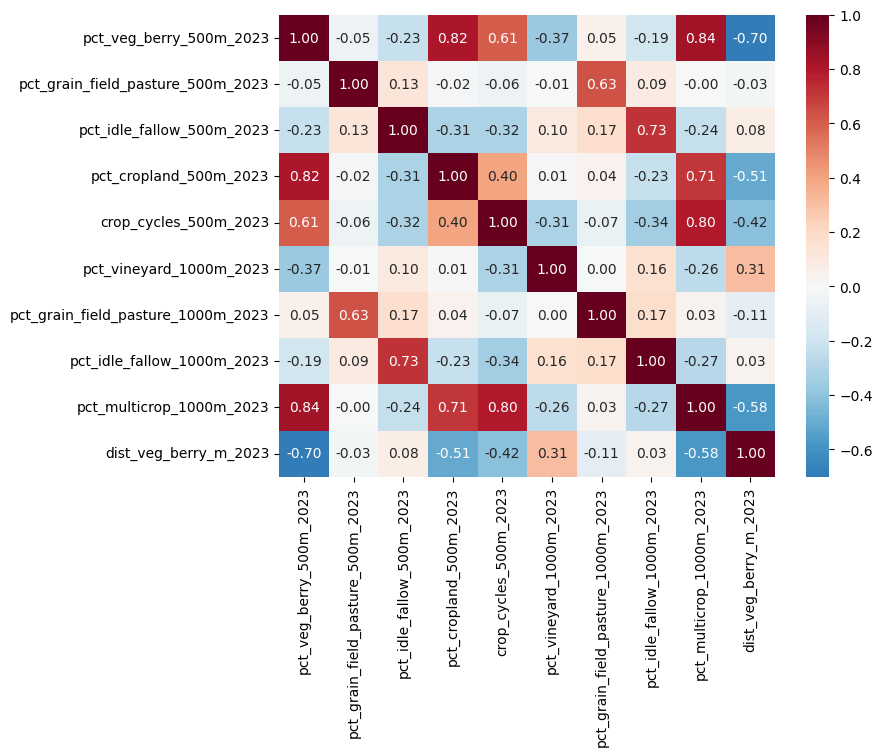

In [11]:
plt.figure(figsize=(8, 6))
sns.heatmap(x.corr(method="spearman"), cmap="RdBu_r", center=0, annot=True, fmt=".2f")
plt.savefig("../../results/eda/crop_mapping/selected_features_corr.png", bbox_inches="tight")
plt.show()

## 5. Model-based check

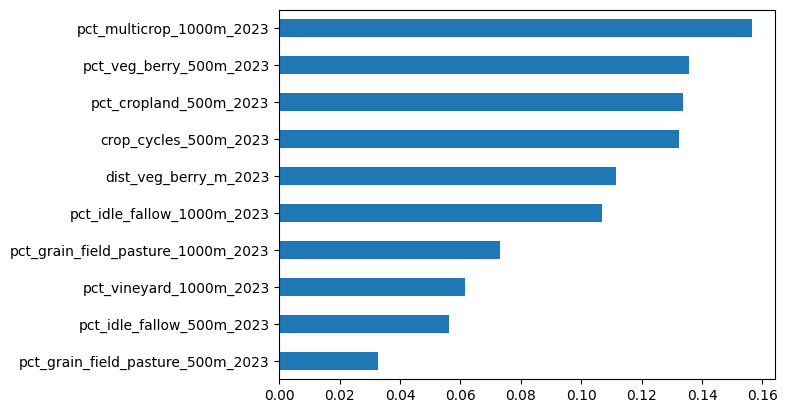

In [12]:
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=0, n_jobs=-1)
rf.fit(x.fillna(0), y)

importance = pd.Series(rf.feature_importances_, index=x.columns).sort_values()
importance.plot.barh()
plt.show()

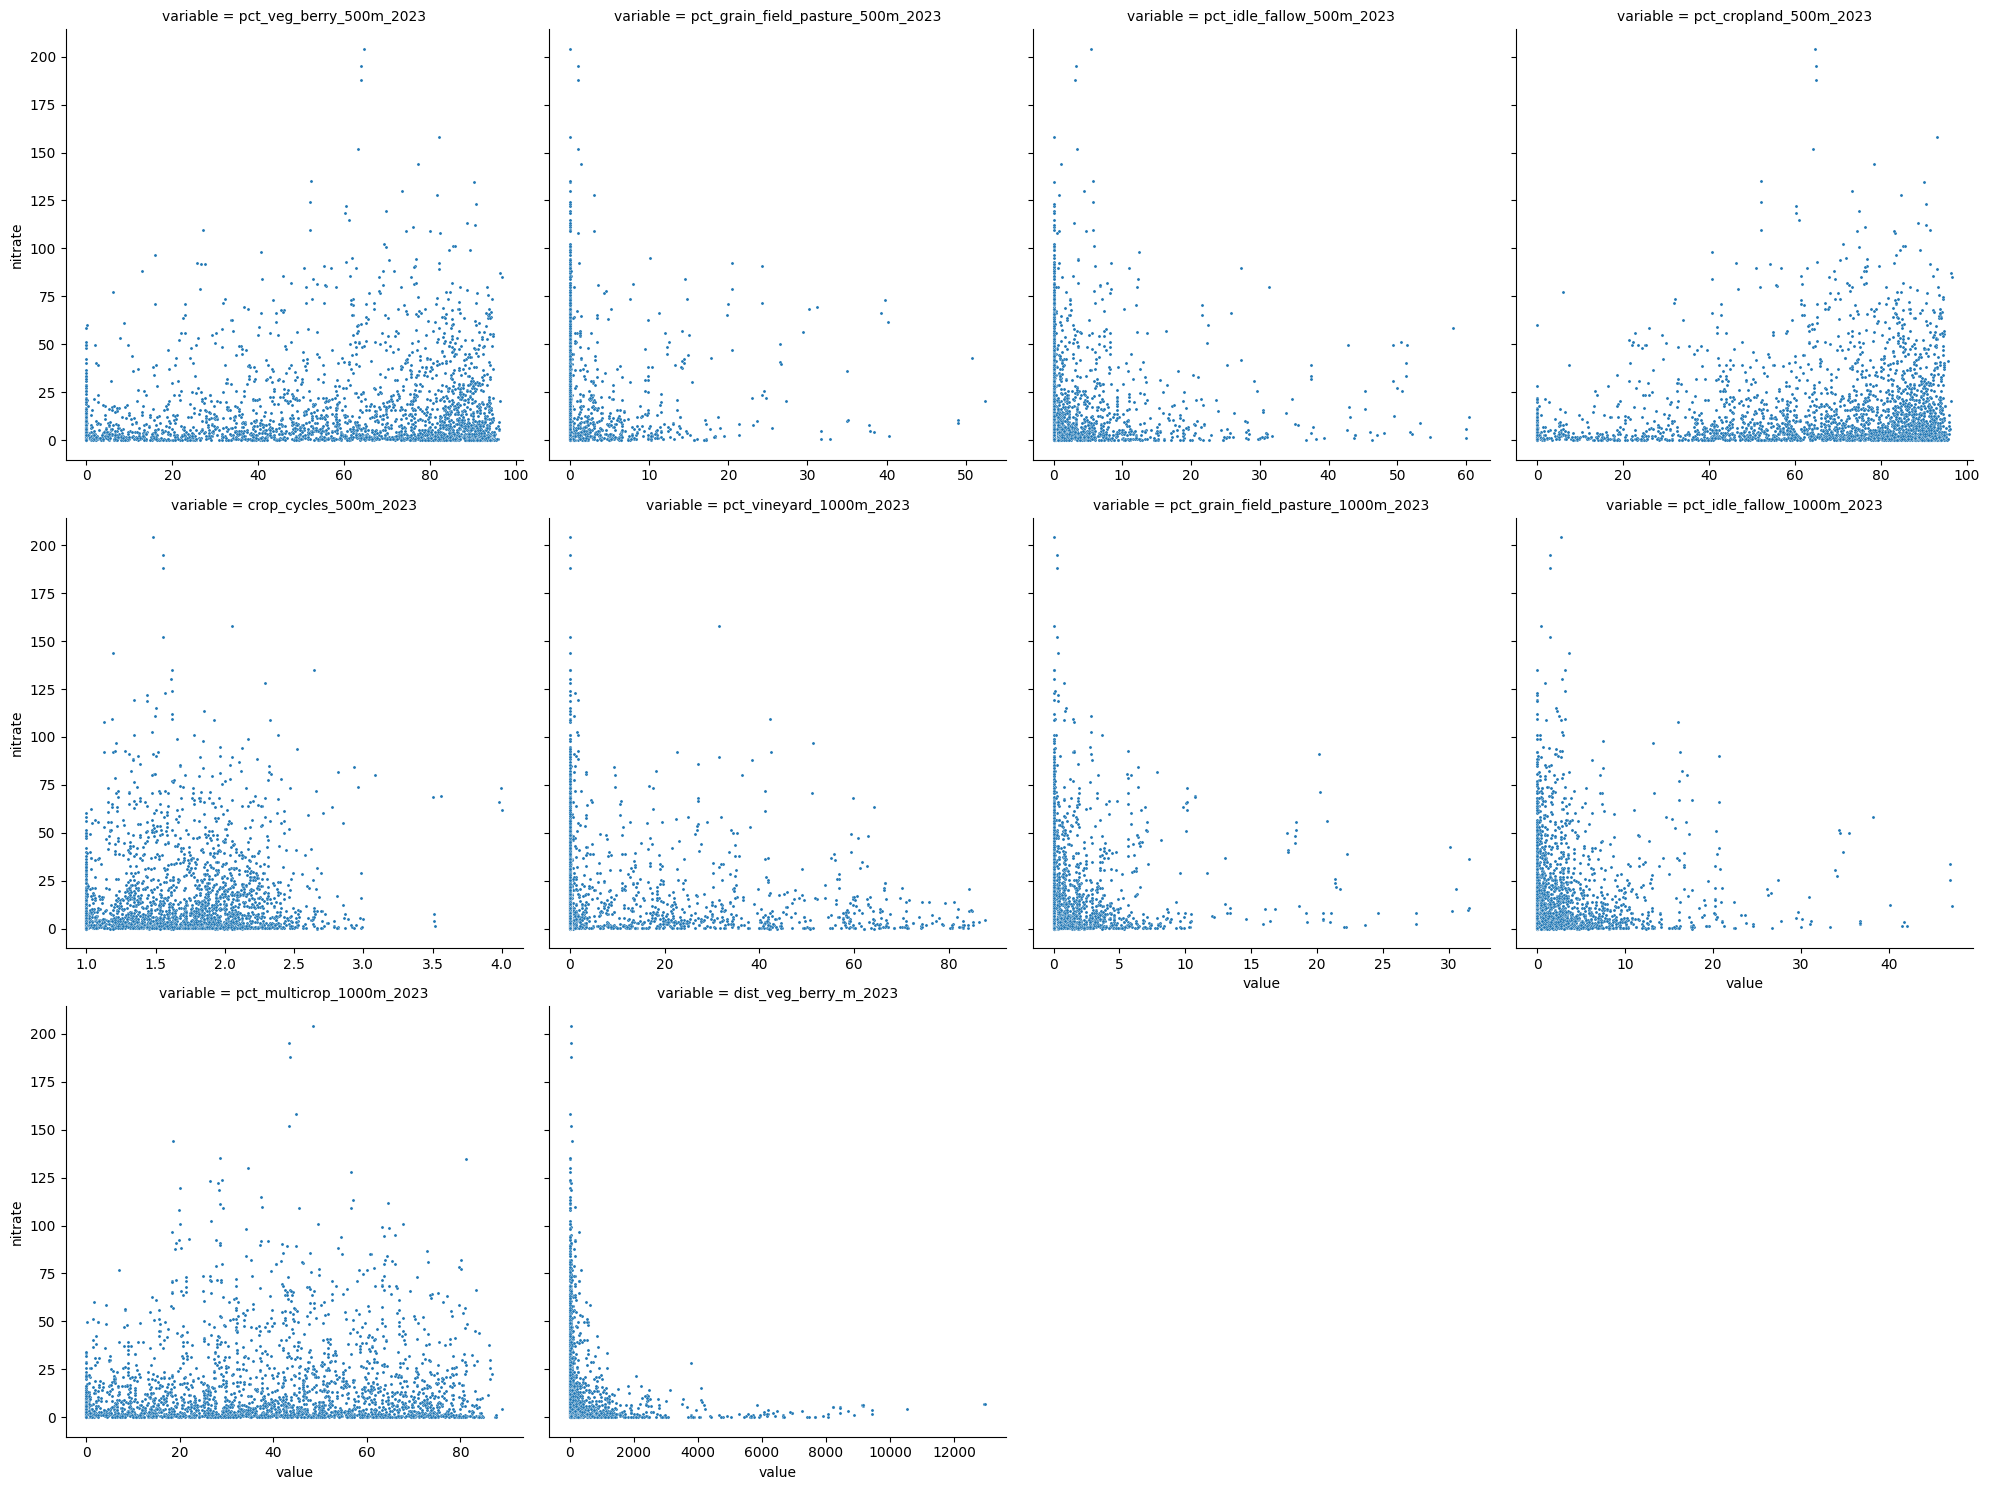

In [13]:
# each kept feature vs nitrate
plot_df = x.assign(nitrate=df["nitrate_median_mgL"]).melt(id_vars="nitrate")
sns.relplot(data=plot_df, x="value", y="nitrate", col="variable", col_wrap=4, s=5, facet_kws={"sharex": False})
plt.show()

In [14]:
# log of every dropped feature and why
pd.DataFrame(log).to_csv("../../results/crop_mapping_feature_selection.csv", index=False)

Each "pct" feature is the percent of a circle around the well covered by that land type. The circle radius (500 m or 1000 m) and the map year are in the name.

- pct_veg_berry_500m_2023: vegetables and berries within 500 m in 2023
- pct_grain_field_pasture_500m_2023: grain, hay, field crops and pasture within 500 m in 2023
- pct_idle_fallow_500m_2023: idle or fallow fields within 500 m in 2023
- pct_cropland_500m_2023: all farmed land added up within 500 m in 2023
- crop_cycles_500m_2023: average number of crops planted per year on the farmland within 500 m in 2023
- pct_vineyard_1000m_2023: vineyards within 1 km in 2023
- pct_grain_field_pasture_1000m_2023: grain, hay, field crops and pasture within 1 km in 2023
- pct_idle_fallow_1000m_2023: idle or fallow fields within 1 km in 2023
- pct_multicrop_1000m_2023: land planted two or more times in 2023, within 1 km
- dist_veg_berry_m_2023: distance in meters to the nearest vegetable or berry field in 2023